In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder
from sklearn.linear_model import LinearRegression
from plotting import plot_surface_2d
np.random.seed(0)
torch.manual_seed(0)

1(a), 1(b): handwritten, see the photo below (also 1a1b.jpg in this folder).

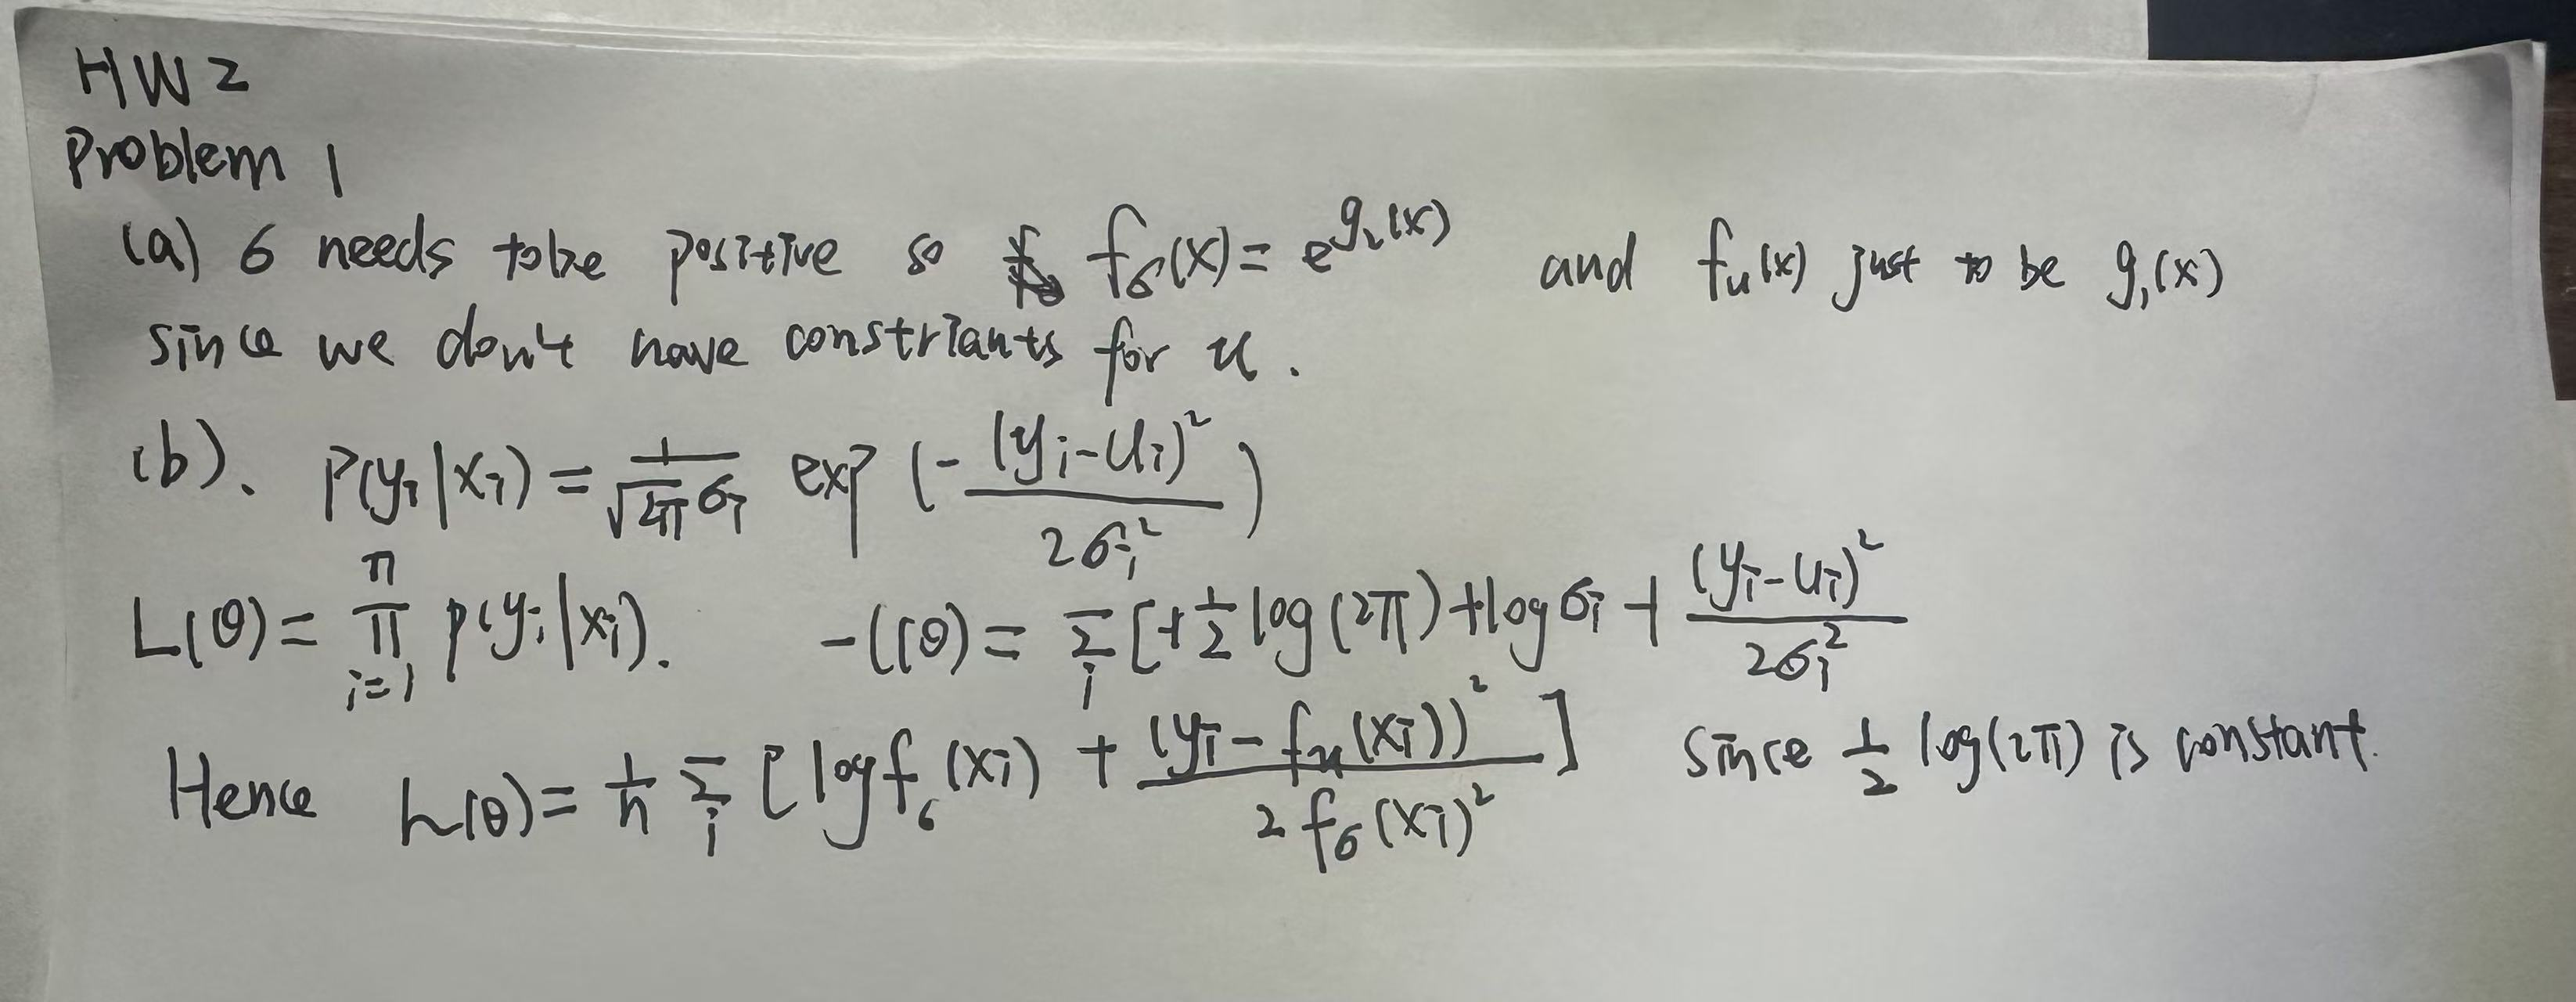

1(c)

In [2]:
d=pd.read_parquet('taxi_trips.parquet')
X = d.drop(columns='trip_duration').values
y=d['trip_duration'].values
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=0)
Xtr, Xva,ytr, yva = train_test_split(Xtr,ytr,test_size=0.2, random_state=0)


print('baseline',np.mean(np.log(ytr.std())+(yte-ytr.mean())**2/(2*ytr.var())))

baseline 2.5419867


In [3]:
Xtr,ytr,Xva,yva,Xte,yte = [torch.tensor(a).float() for a in (Xtr,ytr,Xva,yva,Xte,yte)]
net=nn.Sequential(nn.Linear(7,64),nn.ReLU(), nn.Linear(64,64),nn.ReLU(),nn.Linear(64,2))
def nll(out,y):
    return (out[:,1] + (y-out[:,0])**2/(2*torch.exp(2*out[:,1]))).mean()

opt = torch.optim.Adam(net.parameters(),lr=1e-3)
best=1e9
for ep in range(50):
    p=torch.randperm(len(ytr))
    for i in range(0,len(p),1024):
        b=p[i:i+1024]
        l = nll(net(Xtr[b]),ytr[b])
        opt.zero_grad();l.backward(); opt.step()
    with torch.no_grad(): v=nll(net(Xva),yva).item()
    print(ep,v)
    if v>best: break
    best=v
with torch.no_grad(): print('test', nll(net(Xte),yte).item())

0 2.837684392929077


1 2.3636415004730225


2 2.2685511112213135


3 2.1524441242218018


4 2.0136024951934814


5 1.950685977935791


... (2 outputs left out)

8 1.8700443506240845


9 1.867417573928833


10 1.8513219356536865


11 1.8553388118743896
test 1.8747663497924805


MLP 7 -> 64 -> 64 -> 2. mean = output 1, sigma = exp(output 2). Loss is Gaussian NLL. Split 64/16/20 train/val/test, early stopping on val. Baseline is constant mean and std from train. Test NLL: baseline 2.54, MLP 1.87, so the MLP beats the baseline.

1(d)

The model says Y | x ~ N(mu(x), sigma(x)^2), so P(Y < 45 | x) = Phi((45 - mu(x)) / sigma(x)), where Phi is the standard normal CDF. Just plug in the mu and sigma that the MLP outputs.

1(e)

In [4]:
from scipy.stats import norm
with torch.no_grad(): out=net(Xte)
p = norm.cdf((45-out[:,0].numpy())/np.exp(out[:,1].numpy()))
z=yte.numpy()<45
print('brier',np.mean((p-z)**2))
print("acc", np.mean((p>0.5)==z))
print(z.mean())

brier 0.004605736812802069
acc 0.9940407407053701
0.9954446046738165


Test Brier score = 0.0046, accuracy (threshold 0.5) = 0.994. But 99.5% of test trips are under 45 min, so always predicting "under 45" would already get 0.995 accuracy, which is slightly higher than ours. The scores look good mostly because the event is so common. The normal assumption probably doesn't fit the long right tail of trip times well.

2(a)

In [5]:
df=pd.read_csv("retail.csv")
df['StockCode']=df['StockCode'].astype('category')
df["CustomerID"] = df["CustomerID"].astype("category")
print(df.nunique())

Quantity       302
StockCode     3665
CustomerID    4339
dtype: int64


In [6]:
df['y']=np.log1p(df['Quantity'])
df['s'] = df['StockCode'].cat.codes
df['c']=df['CustomerID'].cat.codes
train,test=train_test_split(df,test_size=0.2,random_state=0)
train, val = train_test_split(train,test_size=0.2,random_state=0)

StockCode has 3665 unique values, CustomerID has 4339. That's high cardinality, so one-hot would need 8004 columns that are mostly zeros. That's too big, so one-hot isn't really feasible. Target encoding or embeddings are better. Quantity is heavy-tailed, so I use log(1+Quantity) with MSE.

2(b)

In [7]:
enc=TargetEncoder(target_type='continuous')
te_tr = enc.fit_transform(train[['s','c']],train['y'])
te_va=enc.transform(val[['s','c']])
te_te=enc.transform(test[['s','c']])
m=LinearRegression().fit(te_tr,train['y'])
print(np.mean((m.predict(te_te)-test['y'])**2))

0.35261791667992226


Linear regression on the 2 target-encoded features, MSE loss on log(1+Quantity). Test MSE = 0.353.

2(c)

In [8]:
s_tr,c_tr,y_tr = torch.tensor(train['s'].values).long(),torch.tensor(train['c'].values).long(),torch.tensor(train['y'].values).float()
s_va,c_va,y_va=torch.tensor(val['s'].values).long(), torch.tensor(val['c'].values).long(), torch.tensor(val['y'].values).float()
s_te, c_te, y_te = torch.tensor(test['s'].values).long(),torch.tensor(test['c'].values).long(),torch.tensor(test['y'].values).float()
x_tr,x_va,x_te=torch.tensor(te_tr).float(),torch.tensor(te_va).float(),torch.tensor(te_te).float()

class Net(nn.Module):
    def __init__(self,use_te):
        super().__init__()
        self.use_te=use_te
        self.e1 = nn.Embedding(df['s'].max()+1,16)
        self.e2=nn.Embedding(df['c'].max()+1, 16)
        self.fc=nn.Sequential(nn.Linear(34 if use_te else 32,64),nn.ReLU(),nn.Linear(64,1))
    def forward(self,s,c,x):
        h=torch.cat([self.e1(s),self.e2(c)],1)
        if self.use_te: h=torch.cat([h,x],1)
        return self.fc(h).squeeze(1)

def fit(model):
    opt=torch.optim.Adam(model.parameters(), lr=1e-3)
    best = 1e9
    for ep in range(50):
        p=torch.randperm(len(y_tr))
        for i in range(0,len(p),1024):
            b = p[i:i+1024]
            l=((model(s_tr[b],c_tr[b],x_tr[b])-y_tr[b])**2).mean()
            opt.zero_grad(); l.backward();opt.step()
        with torch.no_grad(): v=((model(s_va,c_va,x_va)-y_va)**2).mean().item()
        print(ep,v)
        if v>best: break
        best=v
    return model


m1=fit(Net(False))
with torch.no_grad(): print('test',((m1(s_te,c_te,x_te)-y_te)**2).mean().item())

0 0.9057158827781677


1 0.7396401762962341


2 0.6078896522521973


3 0.5090391635894775


4 0.4419156312942505


5 0.39937761425971985


... (22 outputs left out)

28 0.3001929223537445


29 0.29928722977638245


30 0.29804959893226624


31 0.29807931184768677
test 0.29634833335876465


Embedding dim 16. Test MSE = 0.296, better than target encoding (0.353).

2(d)

In [9]:
m2 = fit(Net(True))
with torch.no_grad(): print("test",((m2(s_te,c_te,x_te)-y_te)**2).mean().item())

0 0.4882783889770508


1 0.38269299268722534


2 0.35757479071617126


3 0.34831175208091736


4 0.3428431749343872


5 0.33832302689552307


... (12 outputs left out)

18 0.3069905936717987


19 0.3052643835544586


20 0.30488261580467224


21 0.3062165081501007
test 0.30552199482917786


Test MSE = 0.306, about the same as embeddings only (0.296) and better than target encoding. The TE features don't add much since the embeddings can already learn the category means.

2(e)

The embedding layer learns a vector for each item and each customer. Similar ones get similar vectors, so they can share information, and it's much smaller than one-hot. Target encoding only keeps the mean of each category, so it loses information. That's why embeddings did better on the test set (0.296 vs 0.353).

3(a)

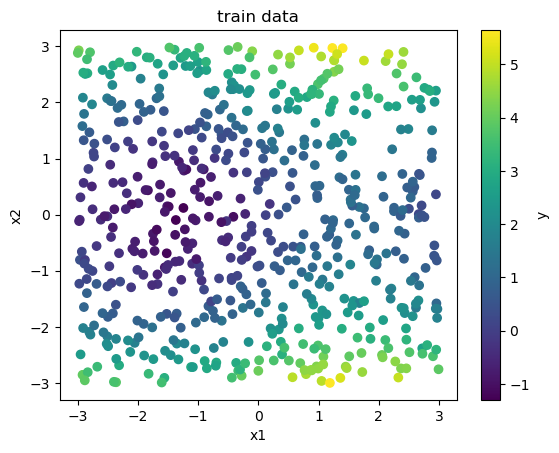

In [10]:
tr=np.loadtxt('train.csv',delimiter=',',skiprows=1)
va = np.loadtxt('val.csv',delimiter=',',skiprows=1)
Xte=np.loadtxt("test.csv", delimiter=",",skiprows=1)
X,y,Xv,yv=tr[:,:2],tr[:,2],va[:,:2],va[:,2]
plt.scatter(X[:,0],X[:,1],c=y);plt.colorbar(label='y'); plt.xlabel('x1');plt.ylabel('x2');plt.title('train data');plt.show()

y is smooth. It's lowest around (-1.5, 0) and highest at the top and bottom edges near x1 = 1.5.

3(b)

[3.3256804571866785, 4.440256450206173, 0.23027763542016214, 0.19190816912881536, 0.03140257827078012, 0.03018194189603318, 0.029461831893491032, 0.02935410969632096, 0.028927861094965715, 0.02840265966749144]
[3.236041071412777, 4.163575468307511, 0.2348451575365477, 0.17270715730868766, 0.03844810383284794, 0.039411072476727836, 0.04092175904256565, 0.04310947717971778, 0.045653414624656656, 0.04529285516793022]


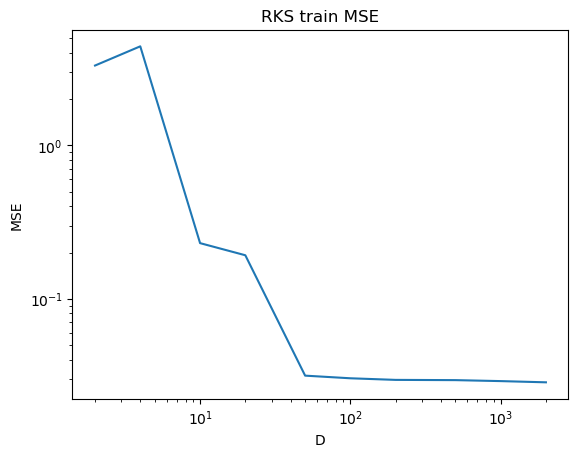

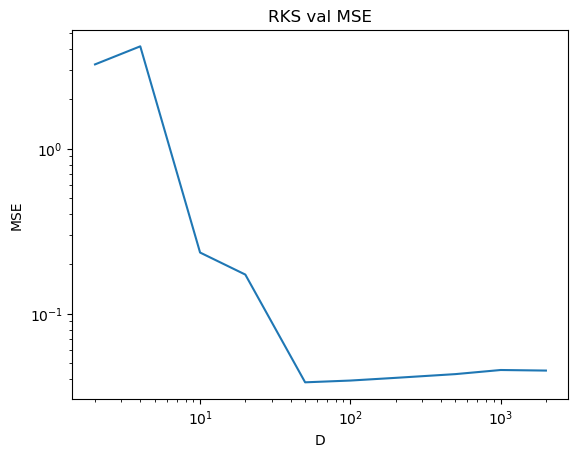

50


In [11]:
def feat(A,W,b):
    return np.hstack([np.sin(A@W+b),np.cos(A@W+b)])

def rks(D,sigma=1,lam=1e-3):
    W=np.random.randn(2,D//2)/sigma
    b = np.random.uniform(0,2*np.pi,D//2)
    Z=feat(X,W,b)
    w=np.linalg.solve(Z.T@Z+lam*np.eye(D), Z.T@y)
    return W,b,w

Ds=[2,4,10,20,50,100,200,500,1000,2000]
rtr,rva=[],[]
for D in Ds:
    W,b,w = rks(D)
    rtr.append(np.mean((feat(X,W,b)@w-y)**2))
    rva.append(np.mean((feat(Xv,W,b)@w - yv)**2))
print(rtr)
print(rva)
plt.plot(Ds,rtr);plt.xscale('log');plt.xlabel('D');plt.ylabel('MSE');plt.yscale('log');plt.title('RKS train MSE');plt.show()
plt.plot(Ds,rva); plt.xscale('log');plt.xlabel('D');plt.ylabel('MSE');plt.yscale('log');plt.title('RKS val MSE');plt.show()
bD=Ds[np.argmin(rva)]
print(bD)

Swept D with sigma = 1, lambda = 1e-3. Train MSE mostly goes down as D gets bigger. Val MSE is lowest at D = 50 and then goes up a bit (overfitting). Best D = 50.

3(c)

[0.2910105884075165, 0.2949548363685608, 0.04198090732097626, 0.0334857776761055, 0.030916456133127213, 0.029513804242014885, 0.02794371359050274, 0.02724490500986576, 0.026315078139305115]
[0.2931186556816101, 0.3082318902015686, 0.05228232219815254, 0.042766980826854706, 0.04149521514773369, 0.03970819339156151, 0.039432600140571594, 0.040216512978076935, 0.04052172973752022]


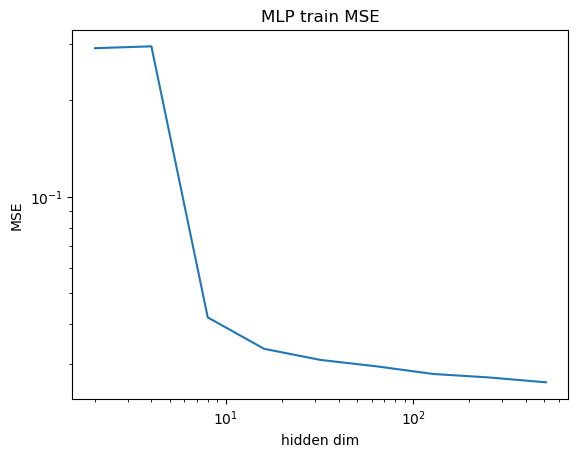

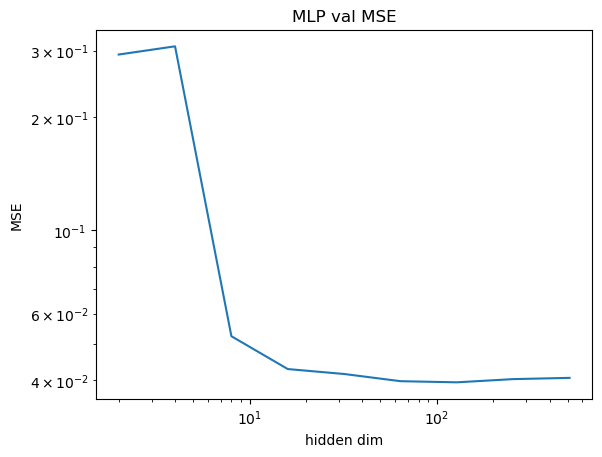

128


In [12]:
Xt,yt=torch.tensor(X).float(),torch.tensor(y).float().view(-1,1)
Xvt, yvt = torch.tensor(Xv).float(),torch.tensor(yv).float().view(-1,1)

def mlp(h):
    torch.manual_seed(0)
    net=nn.Sequential(nn.Linear(2,h),nn.ReLU(),nn.Linear(h,1))
    opt = torch.optim.Adam(net.parameters(),lr=0.01)
    for i in range(2000):
        l=((net(Xt)-yt)**2).mean()
        opt.zero_grad();l.backward();opt.step()
    return net

Hs=[2,4,8,16,32,64,128,256,512]
mtr,mva = [],[]
for h in Hs:
    net=mlp(h)
    with torch.no_grad():
        mtr.append(((net(Xt)-yt)**2).mean().item())
        mva.append(((net(Xvt)-yvt)**2).mean().item())
print(mtr)
print(mva)
plt.plot(Hs,mtr);plt.xscale('log');plt.xlabel('hidden dim');plt.ylabel('MSE');plt.yscale('log');plt.title('MLP train MSE');plt.show()
plt.plot(Hs,mva);plt.xscale('log'); plt.xlabel('hidden dim');plt.ylabel('MSE');plt.yscale('log');plt.title('MLP val MSE');plt.show()
bH=Hs[np.argmin(mva)]
print(bH)

Swept hidden dim with lr = 0.01 and 2000 steps. Train MSE mostly goes down as the hidden dim gets bigger. Val MSE drops a lot until 8, then is about flat, and is lowest at 128 (goes up a little after that). Best is 128.

3(d)

0.038051443063743834
0.039432600140571594


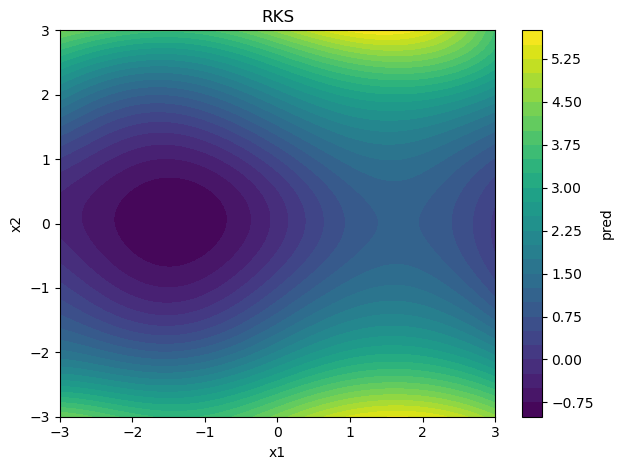

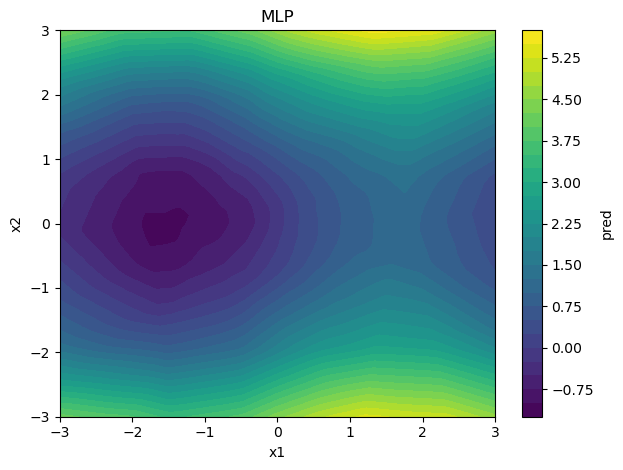

In [13]:
W,b,w=rks(bD)
net = mlp(bH)
print(np.mean((feat(Xv,W,b)@w-yv)**2))
with torch.no_grad():
    print(((net(Xvt)-yvt)**2).mean().item())
    np.savetxt('mlp_test_predictions.csv',net(torch.tensor(Xte).float()).numpy())
np.savetxt('rks_test_predictions.csv', feat(Xte,W,b)@w)

plot_surface_2d(lambda A: feat(A,W,b)@w,(-3,3),(-3,3),title='RKS',filename='rks_surface.png')
plot_surface_2d(net,(-3,3),(-3,3), title='MLP',filename='mlp_surface.png')
plt.show()

Val MSE: RKS 0.038, MLP 0.039, so they're about the same. The function is smooth and 2D, so random sin/cos features work well, and ridge is solved exactly. The MLP has to learn its features with gradient descent. Both surfaces look like the training data in (a): low around (-1.5, 0) and high at the top and bottom edges. RKS builds the surface as a weighted sum of random sin/cos waves, so it comes out very smooth. The MLP builds it from ReLU pieces (piecewise linear), so it has some corners.